# HDD 04 — Masked self-supervised temporal encoder
**VS Code / local Jupyter edition.** 

This is the first implementation of the proposed **Learn** stage: hide SMART values and train a small Transformer to reconstruct them. Save masked reconstruction errors and embeddings for the later **Discover** stage. This notebook does not implement HDBSCAN, combined regime scores, contamination quarantine, or drift adaptation yet.

The June test and real failure labels remain closed. This is one model and one seed, not final research validation. Training data may contain unusual behaviour; no claim that it is a clean healthy reference is made.

## Review of Notebook 03
- 42,578 training windows; 4,410 April calibration windows; 4,642 May development windows.
- Isolation Forest: 35 May flags, 2 drives, 3 consecutive alert episodes.
- Robust deviation reference: 0 May flags.
- Dense autoencoder: 31 May flags, 1 drive, 1 episode.
- Autoencoder stopping MSE decreased from about 0.00852 to 0.00209, with its lowest displayed loss at epoch 50. It reached the epoch limit; early stopping did not demonstrate convergence.
- Temperature +2/+5/spike tests produced 9/40/83 newly flagged windows for Isolation Forest, but 0/0/0 for the autoencoder at its fixed threshold.

These are descriptive results, not accuracy or failure recall. A low reconstruction loss does not establish useful anomaly sensitivity. Neural loss magnitudes and Isolation Forest scores are on different scales. The all-feature average can dilute temperature errors; this notebook therefore saves feature-wise errors as well as the mean score. Feature dominance is a hypothesis to inspect, not an established explanation.


## 1. Dependencies
You already installed most of these for Notebook 03. Run the cell if needed. If VS Code requests a restart, restart the kernel and continue from the next cell. CPU works; an already configured CUDA-enabled PyTorch installation can use a GPU.


In [1]:
%pip -q install "numpy>=1.26,<3" "pandas>=2.2,<3" "scikit-learn>=1.4,<2" "pyarrow>=16" matplotlib tqdm torch


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Locate your existing experiment
The default is the exact local component path saved in your uploaded Notebook 03. Edit it if you moved the repository. The diagnostic prints the complete expected path if a required file is missing. Do not bypass the completion or integrity checks.


In [2]:
from pathlib import Path
import json, hashlib, random, copy, time, platform, os
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm

COMPONENT_ROOT = Path(r"D:/SLIIT/Y4S1/RP/Research/J26-DS-342-/01_component_1_behavioral_drift_genai")
RUN_ID = 'single_model_q1q2_2021_v1'
SSL_ID = 'masked_transformer_v1_seed42'
RUN = COMPONENT_ROOT/'experiments'/RUN_ID

def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as handle:
        for block in iter(lambda:handle.read(1024*1024),b''): h.update(block)
    return h.hexdigest()

complete_path=RUN/'dataset_complete.json'
if not complete_path.is_file():
    raise FileNotFoundError(f'Notebook 02 completion file missing: {complete_path.resolve()}\nUse the same COMPONENT_ROOT and RUN_ID as Notebook 02/03.')
complete=json.loads(complete_path.read_text())
assert complete['status']=='passed'
config_path=COMPONENT_ROOT/'config'/f'{RUN_ID}.json'
splits_path=COMPONENT_ROOT/'data/splits'/f'{RUN_ID}_serials.json'
assert sha256(config_path)==complete['config_sha256'], 'Dataset config changed.'
assert sha256(splits_path)==complete['split_sha256'], 'Drive assignments changed.'
for relative,digest in complete['working_hashes'].items():
    assert sha256(COMPONENT_ROOT/relative)==digest, f'Changed dataset input: {relative}'
cfg=json.loads(config_path.read_text())
FEATURES=cfg['raw_features']; WINDOW_DAYS=cfg['window_days']; SEED=42
FEATURE_ROOT=COMPONENT_ROOT/'data/features'/RUN_ID
OUT=COMPONENT_ROOT/'results'/RUN_ID/SSL_ID
MODEL_DIR=COMPONENT_ROOT/'models/trained'/RUN_ID/SSL_ID
EMBED_DIR=COMPONENT_ROOT/'data/features'/RUN_ID/SSL_ID
for p in [OUT,MODEL_DIR,EMBED_DIR]: p.mkdir(parents=True,exist_ok=True)
prep_path=COMPONENT_ROOT/'models/trained'/f'{RUN_ID}_daily_preprocessing.json'
prep=json.loads(prep_path.read_text())
provenance=json.loads((RUN/'dataset_provenance.json').read_text())
assert sha256(prep_path)==provenance['preprocessing_sha256'], 'Daily preprocessing changed.'
assert prep['features']==FEATURES
assert prep['fit_split']=='train'
print('Component:',COMPONENT_ROOT.resolve())
print('Dataset:',RUN_ID,'| Model experiment:',SSL_ID)


Component: D:\SLIIT\Y4S1\RP\Research\J26-DS-342-\01_component_1_behavioral_drift_genai
Dataset: single_model_q1q2_2021_v1 | Model experiment: masked_transformer_v1_seed42


c:\Users\IMAKA\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Load working windows only
Each sequence has 30 days × 5 attributes. All current windows are fully observed under Notebook 02's strict policy. Keep the observation mask separate from the artificial training mask. A masked input value of zero means the training median in scaled space, not necessarily raw SMART zero; the artificial-mask channel tells the model it was hidden.


In [3]:
X,raw,observed,metadata={},{},{},{}
for split in ['train','calibration','development']:
    folder=FEATURE_ROOT/split
    with np.load(folder/'windows_scaled.npz') as data:
        X[split]=data['X'].astype(np.float32)
        observed[split]=data['observed_mask'].astype(bool)
    with np.load(folder/'windows_raw.npz') as data: raw[split]=data['X'].astype(np.float32)
    metadata[split]=pd.read_parquet(folder/'metadata.parquet')
    assert X[split].shape==(len(metadata[split]),WINDOW_DAYS,len(FEATURES))
    assert observed[split].shape==X[split].shape and observed[split].all()
    assert np.isfinite(X[split]).all() and len(X[split])>0
    print(split,X[split].shape,'| drives:',metadata[split]['serial_number'].nunique())
for a in X:
    for b in X:
        if a!=b: assert set(metadata[a]['serial_number']).isdisjoint(metadata[b]['serial_number'])
print('Only training, calibration and development files loaded.')


train (42578, 30, 5) | drives: 700
calibration (4410, 30, 5) | drives: 147
development (4642, 30, 5) | drives: 150
Only training, calibration and development files loaded.


## 4. Freeze settings and the internal early-stopping cohort
Use exactly the same stopping-serial selection rule as Notebook 03. Those serials are reserved within the training group; they are not the independent development or final test sets. Preprocessing was already fitted on the full training cohort, so this is an internal optimisation check.

The architecture is deliberately small: width 32, four attention heads, two encoder layers. A single-model pilot needs no learned HDD-model embedding because the model identity is constant. Add a model-conditioning strategy when extending across HDD models.

If you change settings, choose a new SSL_ID. Rerunning with unchanged settings reloads the existing best checkpoint instead of training again. This is restart-from-best for inference, not exact interrupted-training resumption.


In [4]:
SETTINGS={
    'seed':SEED,'width':32,'heads':4,'layers':2,'feedforward':64,'dropout':.1,
    'point_mask_probability':.15,'span_days':3,'batch_size':128,
    'max_epochs':50,'patience':8,'learning_rate':1e-3,'weight_decay':1e-5,
    'score_policy':'five fixed diagonal mask partitions; each value hidden and scored exactly once',
    'embedding_policy':'mean of pooled encoder embeddings from the five fixed masked passes',
    'score_quantile':.99,'features':FEATURES,'window_days':WINDOW_DAYS,
    'dataset_config_sha256':sha256(config_path),'preprocessing_sha256':sha256(prep_path),
    'dataset_complete_sha256':sha256(complete_path),
}
settings_path=MODEL_DIR/'settings.json'
if settings_path.exists() and json.loads(settings_path.read_text())!=SETTINGS:
    raise ValueError('Settings differ from the existing experiment. Use a new SSL_ID.')
settings_path.write_text(json.dumps(SETTINGS,indent=2))
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic=True
torch.backends.cudnn.benchmark=False
# Seeds reduce variation, but do not guarantee identical results across devices/releases.
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type=='cpu': torch.set_num_threads(max(1,min(4,os.cpu_count() or 1)))
serials=np.array(sorted(metadata['train']['serial_number'].unique()))
np.random.default_rng(SEED+2).shuffle(serials)
stop_ids=set(serials[:max(1,int(.15*len(serials)))])
stop_select=metadata['train']['serial_number'].isin(stop_ids).to_numpy()
fit_select=~stop_select
assert fit_select.any() and stop_select.any()
(MODEL_DIR/'internal_stopping_serials.json').write_text(json.dumps(sorted(str(s) for s in stop_ids),indent=2))
print('Device:',DEVICE,'| fit windows:',int(fit_select.sum()),'| stopping windows:',int(stop_select.sum()))


Device: cpu | fit windows: 36207 | stopping windows: 6371


## 5. Masks and Transformer
Training hides random observed cells plus a short span from one randomly chosen feature per window. Loss is computed **only on artificially hidden observed values**. Visible target values never pass through the encoder at hidden positions.

The encoder input concatenates corrupted values, the original observation mask, and the artificial hide mask, then adds a learned position vector. Bidirectional attention is appropriate for reconstructing within the trailing historical window: every day in the window is already available at its scoring endpoint. It does not use days after that endpoint.

At evaluation, five fixed mask patterns cover each cell once. For each day, one of the five features is hidden per pass, with the feature cycling over days. This avoids scoring a value that the model was shown. Embeddings are the mean of pooled hidden states across these same passes.

The partition schedule is an initial design choice. It leaves correlated features visible, so duplicated/correlated counters can make reconstruction too easy. Later compare feature-group and span masking as a declared ablation. Attention weights are not causal explanations.


In [5]:
def training_mask(batch, generator):
    b,t,f=batch.shape
    hide=torch.rand((b,t,f),generator=generator)<SETTINGS['point_mask_probability']
    span=min(SETTINGS['span_days'],t)
    starts=torch.randint(0,t-span+1,(b,),generator=generator)
    channels=torch.randint(0,f,(b,),generator=generator)
    for row in range(b): hide[row,starts[row]:starts[row]+span,channels[row]]=True
    assert hide.flatten(1).any(1).all()
    return hide

def fixed_partitions(t,f):
    grid=(torch.arange(t)[:,None]+torch.arange(f)[None,:])%f
    masks=[grid.eq(k) for k in range(f)]
    assert torch.stack(masks).sum(0).eq(1).all()
    return masks

PARTITIONS=fixed_partitions(WINDOW_DAYS,len(FEATURES))

class MaskedTelemetryTransformer(nn.Module):
    def __init__(self,t,f,width,heads,layers,feedforward,dropout):
        super().__init__()
        self.input_projection=nn.Linear(3*f,width)
        self.position=nn.Parameter(torch.empty(1,t,width))
        nn.init.normal_(self.position,std=.02)
        layer=nn.TransformerEncoderLayer(d_model=width,nhead=heads,
            dim_feedforward=feedforward,dropout=dropout,batch_first=True,
            norm_first=False,activation='gelu')
        self.encoder=nn.TransformerEncoder(layer,num_layers=layers,enable_nested_tensor=False)
        # Independently initialise cloned encoder blocks, as recommended by PyTorch.
        for block in self.encoder.layers:
            for parameter in block.parameters():
                if parameter.dim()>1: nn.init.xavier_uniform_(parameter)
        self.output_projection=nn.Linear(width,f)
    def forward(self,values,original_observed,hide):
        corrupted=values.masked_fill(hide | ~original_observed,0.)
        inputs=torch.cat([corrupted,original_observed.float(),hide.float()],dim=-1)
        hidden=self.encoder(self.input_projection(inputs)+self.position[:,:values.shape[1]])
        reconstruction=self.output_projection(hidden)
        embedding=hidden.mean(dim=1)
        return reconstruction,embedding

model=MaskedTelemetryTransformer(WINDOW_DAYS,len(FEATURES),SETTINGS['width'],SETTINGS['heads'],
    SETTINGS['layers'],SETTINGS['feedforward'],SETTINGS['dropout']).to(DEVICE)
parameter_count=sum(p.numel() for p in model.parameters())
assert parameter_count<100000
print('Trainable parameters:',parameter_count)

# Sanity check: hidden target values cannot influence a reconstruction pass.
model.eval()
with torch.no_grad():
    demo=torch.tensor(X['train'][:2],device=DEVICE)
    obs=torch.ones_like(demo,dtype=torch.bool)
    hide=PARTITIONS[0].to(DEVICE).expand_as(demo)
    changed=demo.clone(); changed[hide]+=100
    prediction,_=model(demo,obs,hide)
    changed_prediction,_=model(changed,obs,hide)
    assert torch.allclose(prediction,changed_prediction), 'Hidden-target leakage detected.'
print('Mask partition and hidden-input checks passed.')


Trainable parameters: 18725
Mask partition and hidden-input checks passed.


## 6. Deterministic masked scoring
Reconstruct every cell while it is hidden, once per window. Save errors per feature, plus their unweighted mean as the initial anomaly score. These are squared errors in training-scaled space, not physical units.

For optimisation, evaluate the same fixed mask policy on a fixed internal stopping subset of at most 2,048 windows, selected without labels. Full split scoring happens after training. This limits CPU cost; it does not make overlapping windows independent.


In [6]:
@torch.no_grad()
def infer_scaled(values, description='Scoring', progress=False):
    assert values.ndim==3 and np.isfinite(values).all()
    model.eval()
    feature_errors,embeddings=[],[]
    loader=DataLoader(TensorDataset(torch.from_numpy(np.asarray(values,dtype=np.float32))),
        batch_size=SETTINGS['batch_size'],shuffle=False,num_workers=0)
    iterator=tqdm(loader,desc=description,leave=False) if progress else loader
    for (batch,) in iterator:
        batch=batch.to(DEVICE)
        obs=torch.ones_like(batch,dtype=torch.bool)
        errors=torch.zeros_like(batch)
        embedding_sum=None
        for mask in PARTITIONS:
            hide=mask.to(DEVICE).unsqueeze(0).expand_as(batch)
            reconstructed,embedding=model(batch,obs,hide)
            errors+=torch.where(hide,(reconstructed-batch).square(),torch.zeros_like(batch))
            embedding_sum=embedding if embedding_sum is None else embedding_sum+embedding
        if not torch.isfinite(errors).all(): raise ValueError('Nonfinite reconstruction error.')
        feature_errors.append(errors.mean(dim=1).cpu().numpy())
        embeddings.append((embedding_sum/len(PARTITIONS)).cpu().numpy())
    errors=np.concatenate(feature_errors); latent=np.concatenate(embeddings)
    assert np.isfinite(errors).all() and np.isfinite(latent).all()
    return {'score':errors.mean(axis=1),'feature_errors':errors,'embeddings':latent}

stop_values=X['train'][stop_select]
if len(stop_values)>2048:
    stop_values=stop_values[np.random.default_rng(SEED+4).choice(len(stop_values),2048,replace=False)]
print('Fixed internal stopping subset:',len(stop_values))


Fixed internal stopping subset: 2048


## 7. Train, or reuse an existing best checkpoint
The masked objective is harder than an ordinary autoencoder, so its loss magnitude is not directly comparable to Notebook 03's visible-input reconstruction loss. Watch for decreasing stopping loss, numerical failures, and the final best epoch.

Checkpointing happens each time stopping loss improves. Rerunning reuses the saved best model and its saved history. If training was interrupted, the saved history may be partial; this notebook reports that. For a fresh training run, choose a new SSL_ID. It does not silently overwrite an existing checkpoint.

No contamination quarantine is applied in this first encoder run. Add and test the proposal's training-only quarantine/retraining stage as a later ablation; do not use real failure flags for it.


In [7]:
checkpoint_path=MODEL_DIR/'best_encoder.pt'
training_record_path=MODEL_DIR/'training_record.json'
settings_hash=sha256(settings_path)
if checkpoint_path.exists():
    # Load only this locally generated, trusted state dictionary.
    checkpoint=torch.load(checkpoint_path,map_location=DEVICE,weights_only=True)
    assert checkpoint['settings_sha256']==settings_hash
    model.load_state_dict(checkpoint['state_dict'])
    history=checkpoint['history']
    best_epoch=checkpoint['best_epoch']
    best_loss=checkpoint['best_stopping_loss']
    training_record=json.loads(training_record_path.read_text()) if training_record_path.exists() else {'completed':False,'reason':'interrupted after best checkpoint'}
    print('Loaded existing checkpoint. Best epoch:',best_epoch,'| loss:',best_loss)
    print('Training record:',training_record)
else:
    optimizer=torch.optim.AdamW(model.parameters(),lr=SETTINGS['learning_rate'],weight_decay=SETTINGS['weight_decay'])
    fit_loader=DataLoader(TensorDataset(torch.from_numpy(X['train'][fit_select])),
        batch_size=SETTINGS['batch_size'],shuffle=True,num_workers=0,
        generator=torch.Generator().manual_seed(SEED))
    mask_generator=torch.Generator().manual_seed(SEED+10)
    history=[]; best_loss=float('inf'); best_epoch=0; stale=0
    started=time.perf_counter()
    for epoch in range(1,SETTINGS['max_epochs']+1):
        model.train(); total_squared=0.; hidden_count=0
        for (cpu_batch,) in tqdm(fit_loader,desc=f'Epoch {epoch}',leave=False):
            hide=training_mask(cpu_batch,mask_generator).to(DEVICE)
            batch=cpu_batch.to(DEVICE); obs=torch.ones_like(batch,dtype=torch.bool)
            prediction,_=model(batch,obs,hide)
            error=(prediction-batch).square()
            loss=error[hide & obs].mean()
            if not torch.isfinite(loss): raise ValueError('Nonfinite training loss. Inspect data and scaling.')
            optimizer.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),1.)
            optimizer.step()
            total_squared+=error[hide & obs].detach().sum().item(); hidden_count+=int(hide.sum().item())
        stopping_loss=float(infer_scaled(stop_values)['score'].mean())
        history.append({'epoch':epoch,'training_masked_mse':total_squared/hidden_count,
            'stopping_fixed_mask_mse':stopping_loss})
        print(f'Epoch {epoch:02d} | masked train {total_squared/hidden_count:.6f} | stop {stopping_loss:.6f}')
        if stopping_loss<best_loss-1e-6:
            best_loss=stopping_loss; best_epoch=epoch; stale=0
            checkpoint={'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},
                'settings_sha256':settings_hash,'best_epoch':best_epoch,'best_stopping_loss':best_loss,
                'history':copy.deepcopy(history)}
            temporary=checkpoint_path.with_suffix('.pt.tmp')
            torch.save(checkpoint,temporary); temporary.replace(checkpoint_path)
        else: stale+=1
        if stale>=SETTINGS['patience']: break
    training_record={'completed':True,'epochs_completed':len(history),'best_epoch':best_epoch,
        'best_stopping_loss':best_loss,'hit_epoch_limit':len(history)==SETTINGS['max_epochs'],
        'elapsed_seconds':time.perf_counter()-started,'history':history}
    training_record_path.write_text(json.dumps(training_record,indent=2))
    checkpoint=torch.load(checkpoint_path,map_location=DEVICE,weights_only=True)
    model.load_state_dict(checkpoint['state_dict'])
pd.DataFrame(training_record.get('history',history)).to_csv(OUT/'training_history.csv',index=False)
print('Best encoder ready. Best epoch:',best_epoch,'| masked stopping MSE:',best_loss)


Epoch 01 | masked train 0.060847 | stop 0.009018


Epoch 02 | masked train 0.020050 | stop 0.009152


Epoch 03 | masked train 0.014689 | stop 0.008652


Epoch 04 | masked train 0.012803 | stop 0.008779


Epoch 05 | masked train 0.011901 | stop 0.008340


...

Epoch 33 | masked train 0.006275 | stop 0.004950


Epoch 34 | masked train 0.006564 | stop 0.004872


Epoch 35 | masked train 0.006229 | stop 0.004941


Epoch 36 | masked train 0.006125 | stop 0.004897


Epoch 37 | masked train 0.006339 | stop 0.005172
Best encoder ready. Best epoch: 29 | masked stopping MSE: 0.00486311549320817


## 8. Save embeddings, errors and calibrated alerts
The reconstruction-only score is an intermediate detector. It is not yet the combined reconstruction/regime-distance/transition score. Calibrate its threshold using April only, with the same 99th-percentile pilot policy as Notebook 03.

The saved embeddings have one row per metadata row. Clustering must later fit on training embeddings only; calibration/development are transformed/assigned with the frozen training pipeline. A cluster cannot be called healthy or failing without evidence.


In [8]:
inference={}; rows=[]
for split in ['train','calibration','development']:
    inference[split]=infer_scaled(X[split],description=split,progress=True)
threshold=float(np.quantile(inference['calibration']['score'],SETTINGS['score_quantile'],method='higher'))

def group_events(table):
    rows=[]
    for serial,part in table.loc[table['is_anomaly_candidate']].groupby('serial_number'):
        part=part.sort_values('end_date').copy()
        groups=part['end_date'].diff().dt.days.ne(1).cumsum()
        for _,block in part.groupby(groups):
            rows.append({'serial_number':serial,'first_alert':block['end_date'].min(),
                'last_alert':block['end_date'].max(),'flagged_days':len(block)})
    return pd.DataFrame(rows,columns=['serial_number','first_alert','last_alert','flagged_days'])

for split,result in inference.items():
    folder=EMBED_DIR/split; folder.mkdir(exist_ok=True)
    np.savez_compressed(folder/'representations.npz',embeddings=result['embeddings'],
        feature_errors=result['feature_errors'],reconstruction_score=result['score'])
    metadata[split].to_parquet(folder/'metadata.parquet',index=False)
    table=metadata[split].copy(); table['anomaly_score']=result['score']
    table['threshold']=threshold; table['is_anomaly_candidate']=result['score']>threshold
    for j,feature in enumerate(FEATURES): table[feature+'_reconstruction_mse']=result['feature_errors'][:,j]
    table['largest_error_attribute']=[FEATURES[j] for j in result['feature_errors'].argmax(axis=1)]
    table.to_csv(OUT/f'{split}_scores.csv',index=False)
    events=group_events(table); events.to_csv(OUT/f'{split}_events.csv',index=False)
    rows.append({'detector':'masked_transformer','split':split,'windows':len(table),
        'drives_scored':table['serial_number'].nunique(),'flagged_windows':int(table['is_anomaly_candidate'].sum()),
        'flagged_percent':100*table['is_anomaly_candidate'].mean(),
        'drives_with_flags':table.loc[table['is_anomaly_candidate'],'serial_number'].nunique(),
        'alert_episodes':len(events)})
alert_summary=pd.DataFrame(rows)
alert_summary.to_csv(OUT/'alert_burden.csv',index=False)
(MODEL_DIR/'threshold.json').write_text(json.dumps({'threshold':threshold,
    'calibration_split':'April','quantile':SETTINGS['score_quantile'],'checkpoint_sha256':sha256(checkpoint_path)},indent=2))
display(alert_summary.round(3))
print('Frozen reconstruction threshold:',threshold)
print('Feature-wise errors are deviation evidence, not causal explanations.')


,detector,split,windows,drives_scored,flagged_windows,flagged_percent,drives_with_flags,alert_episodes
0,masked_transformer,train,42578,700,0,0.000,0,0
1,masked_transformer,calibration,4410,147,44,0.998,2,2
2,masked_transformer,development,4642,150,0,0.000,0,0


Frozen reconstruction threshold: 2.476930618286133
Feature-wise errors are deviation evidence, not causal explanations.


## 9. Repeat Notebook 03's development perturbations
Use the same raw windows and injection definitions, with frozen daily preprocessing and threshold. Do not retrain. These window-wise tests are not coherent stream simulations; do not use them to claim drift delay or failure-event recall.

Alongside score changes, save attribute-error changes so that a weak aggregate response can be investigated. The frozen-value perturbation can make a naturally predictable temperature sequence easier to reconstruct. Its lack of detection does not automatically mean a software fault.


In [9]:
def scale_raw(values):
    transformed=values.astype(np.float64,copy=True)
    assert np.isfinite(transformed).all() and (transformed>=0).all()
    for feature in prep['log_features']:
        j=FEATURES.index(feature); transformed[...,j]=np.log1p(transformed[...,j])
    return ((transformed-np.array(prep['center']))/np.array(prep['scale'])).astype(np.float32)

np.testing.assert_allclose(scale_raw(raw['development']),X['development'],rtol=1e-5,atol=1e-6)
base=raw['development']; temperature=FEATURES.index('smart_194_raw')
original=inference['development']['score']; original_flag=original>threshold

def perturbation(name):
    modified=base.copy()
    if name=='temperature_plus_2_last_7_days': modified[:,-7:,temperature]+=2
    elif name=='temperature_plus_5_last_7_days': modified[:,-7:,temperature]+=5
    elif name=='temperature_spike_plus_10': modified[:,-1,temperature]+=10
    elif name=='temperature_frozen_last_7_days': modified[:,-7:,temperature]=modified[:,-8,temperature][:,None]
    elif name=='temperature_alignment_break':
        rng=np.random.default_rng(SEED+3)
        for i in range(len(modified)): modified[i,-7:,temperature]=rng.permutation(modified[i,-7:,temperature])
    else: raise ValueError(name)
    return modified

experiments=['temperature_plus_2_last_7_days','temperature_plus_5_last_7_days',
    'temperature_spike_plus_10','temperature_frozen_last_7_days','temperature_alignment_break']
sensitivity_rows=[]
for experiment in experiments:
    changed_raw=perturbation(experiment)
    changed=infer_scaled(scale_raw(changed_raw),description=experiment,progress=True)
    actually_changed=np.any(changed_raw!=base,axis=(1,2))
    eligible=(~original_flag)&actually_changed
    modified_flag=changed['score']>threshold
    newly=eligible&modified_flag
    row={'experiment':experiment,'detector':'masked_transformer','windows':len(base),
        'actually_changed_windows':int(actually_changed.sum()),
        'median_score_change':float(np.median(changed['score']-original)),
        'percent_score_increased':100*float(((changed['score']-original)>1e-10).mean()),
        'original_flagged':int(original_flag.sum()),'modified_flagged':int(modified_flag.sum()),
        'eligible_originally_unflagged_changed':int(eligible.sum()),'newly_flagged':int(newly.sum()),
        'new_alert_percent_of_eligible':100*float(newly.sum()/eligible.sum()) if eligible.any() else None,
        'median_temperature_error_change':float(np.median(changed['feature_errors'][:,temperature]-inference['development']['feature_errors'][:,temperature]))}
    sensitivity_rows.append(row)
    detail=metadata['development'].copy()
    detail['original_score']=original; detail['modified_score']=changed['score']
    detail['original_flag']=original_flag; detail['modified_flag']=modified_flag
    detail.to_csv(OUT/f'{experiment}_scores.csv',index=False)
sensitivity=pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(OUT/'synthetic_sensitivity.csv',index=False)
display(sensitivity.round(5))


,experiment,detector,windows,actually_changed_windows,median_score_change,percent_score_increased,original_flagged,modified_flagged,eligible_originally_unflagged_changed,newly_flagged,new_alert_percent_of_eligible,median_temperature_error_change
0,temperature_plus_2_last_7_days,masked_transformer,4642,4642,0.00024,85.58811,0,0,4642,0,0.0,0.00122
1,temperature_plus_5_last_7_days,masked_transformer,4642,4642,0.00176,97.95347,0,0,4642,0,0.0,0.00882
2,temperature_spike_plus_10,masked_transformer,4642,4642,0.01018,99.26756,0,0,4642,0,0.0,0.05098
3,temperature_frozen_last_7_days,masked_transformer,4642,4460,-0.00034,0.53856,0,0,4460,0,0.0,-0.00167
4,temperature_alignment_break,masked_transformer,4642,4223,0.00002,57.28134,0,0,4223,0,0.0,0.00011


## 10. Compare with saved baselines and inspect error contributions
Same development window metadata must match before comparing. No baseline models need loading. Equal April quantiles provide approximately similar **calibration alert budgets**, not proven equal false-positive rates.

The feature-error chart shows training-scaled mean squared error. It is useful for spotting a dominant attribute, not for assigning causal responsibility. The Transformer needs to earn its extra complexity; negative results are valid research evidence.


,detector,split,windows,drives_scored,flagged_windows,flagged_percent,drives_with_flags
2,isolation_forest,development,4642,150,35,0.754,2
5,robust_deviation,development,4642,150,0,0.000,0
8,dense_autoencoder,development,4642,150,31,0.668,1
11,masked_transformer,development,4642,150,0,0.000,0


,experiment,detector,newly_flagged,new_alert_percent_of_eligible
0,temperature_plus_2_last_7_days,isolation_forest,9,0.195
1,temperature_plus_2_last_7_days,robust_deviation,0,0.000
2,temperature_plus_2_last_7_days,dense_autoencoder,0,0.000
3,temperature_plus_5_last_7_days,isolation_forest,40,0.868
4,temperature_plus_5_last_7_days,robust_deviation,1,0.022
5,temperature_plus_5_last_7_days,dense_autoencoder,0,0.000
6,temperature_spike_plus_10,isolation_forest,83,1.802
7,temperature_spike_plus_10,robust_deviation,67,1.443
8,temperature_spike_plus_10,dense_autoencoder,0,0.000
9,temperature_frozen_last_7_days,isolation_forest,2,0.045


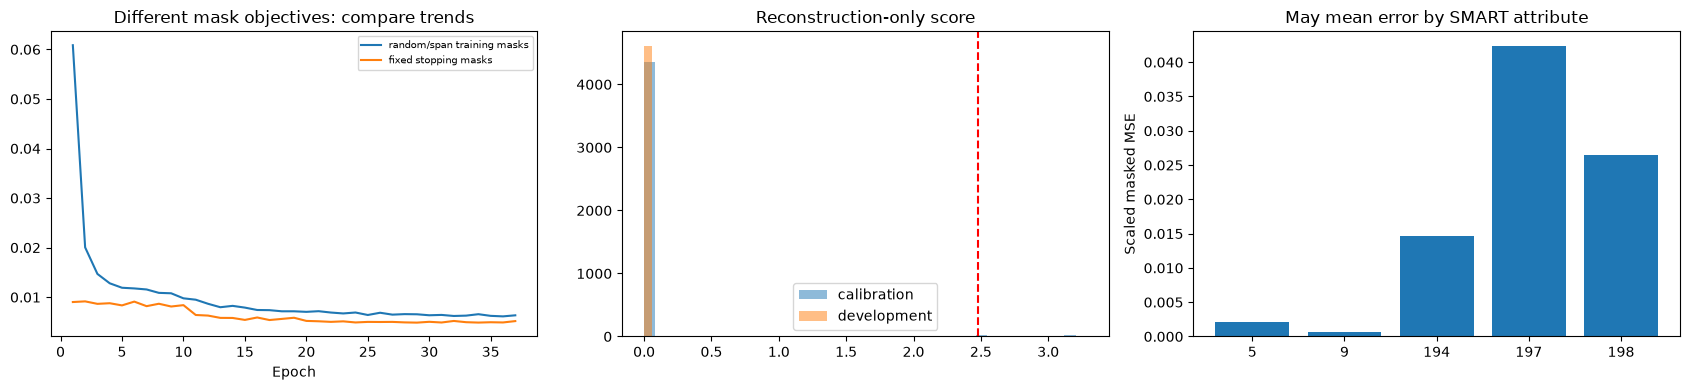

In [10]:
BASELINE=COMPONENT_ROOT/'results'/RUN_ID/'baselines_v1'
for name in ['isolation_forest','robust_deviation','dense_autoencoder']:
    path=BASELINE/f'{name}_development_scores.csv'
    if not path.exists(): raise FileNotFoundError(f'Missing Notebook 03 output: {path}')
    old=pd.read_csv(path,parse_dates=['start_date','end_date'],dtype={'serial_number':str})
    pd.testing.assert_frame_equal(old[['serial_number','start_date','end_date']].reset_index(drop=True),
        metadata['development'][['serial_number','start_date','end_date']].reset_index(drop=True),check_dtype=False)
baseline_burden=pd.read_csv(BASELINE/'alert_burden.csv')
comparison=pd.concat([baseline_burden,alert_summary],ignore_index=True)
comparison.to_csv(OUT/'baseline_comparison_alerts.csv',index=False)
display(comparison.loc[comparison['split'].eq('development')].drop(columns=['alert_episodes'],errors='ignore').round(3))
baseline_sensitivity=pd.read_csv(BASELINE/'synthetic_sensitivity.csv')
comparison_sensitivity=pd.concat([baseline_sensitivity,sensitivity],ignore_index=True)
comparison_sensitivity.to_csv(OUT/'baseline_comparison_sensitivity.csv',index=False)
display(comparison_sensitivity[['experiment','detector','newly_flagged','new_alert_percent_of_eligible']].round(3))

fig,axes=plt.subplots(1,3,figsize=(17,4))
history_table=pd.read_csv(OUT/'training_history.csv')
axes[0].plot(history_table['epoch'],history_table['training_masked_mse'],label='random/span training masks')
axes[0].plot(history_table['epoch'],history_table['stopping_fixed_mask_mse'],label='fixed stopping masks')
axes[0].set_title('Different mask objectives: compare trends'); axes[0].set_xlabel('Epoch'); axes[0].legend(fontsize=7)
for split in ['calibration','development']: axes[1].hist(inference[split]['score'],bins=40,alpha=.5,label=split)
axes[1].axvline(threshold,color='red',linestyle='--'); axes[1].set_title('Reconstruction-only score'); axes[1].legend()
axes[2].bar(np.arange(len(FEATURES)),inference['development']['feature_errors'].mean(axis=0))
axes[2].set_xticks(np.arange(len(FEATURES)),[f.replace('smart_','').replace('_raw','') for f in FEATURES])
axes[2].set_title('May mean error by SMART attribute'); axes[2].set_ylabel('Scaled masked MSE')
fig.tight_layout(); fig.savefig(OUT/'encoder_diagnostics.png',dpi=180,bbox_inches='tight'); plt.show()


## 11. Verify saved representations and finish
Store version and checksum information so Notebook 05 can reuse the exact encoder and embedding order. No HDBSCAN conclusions are made here.

The next step is **HDD_05_Regime_Discovery.ipynb**: fit any embedding normalisation/PCA and HDBSCAN on training embeddings only; assign held-out windows with the frozen pipeline; inspect cluster profiles, persistence, noise fraction and stability. Do not choose cluster settings from June. Do not normalise unusual counter patterns into a healthy regime without checking evidence.


In [11]:
representation_files={}
for split in ['train','calibration','development']:
    folder=EMBED_DIR/split
    with np.load(folder/'representations.npz') as data:
        assert data['embeddings'].shape==(len(metadata[split]),SETTINGS['width'])
        assert data['feature_errors'].shape==(len(metadata[split]),len(FEATURES))
        for key in data.files: assert np.isfinite(data[key]).all()
    pd.testing.assert_frame_equal(pd.read_parquet(folder/'metadata.parquet'),metadata[split])
    for path in folder.iterdir():
        if path.is_file(): representation_files[str(path.relative_to(COMPONENT_ROOT))]=sha256(path)
record={
    'created_utc':datetime.now(timezone.utc).isoformat(),'run_id':RUN_ID,'ssl_id':SSL_ID,
    'settings':SETTINGS,'parameter_count':parameter_count,'best_epoch':best_epoch,
    'best_stopping_loss':best_loss,'training_record':training_record,
    'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'torch':str(torch.__version__)},
    'device':str(DEVICE),'checkpoint_sha256':sha256(checkpoint_path),
    'representation_files':representation_files,'failure_labels_used':False,'sealed_test_opened':False,
    'score_is_failure_probability':False,
    'limitations':['one seed and one HDD model','dependent windows','unlabeled contaminated training possible',
        'fixed masking schedule may exploit correlated channels','no quarantine/retraining yet',
        'reconstruction-only score; no regimes or drift policy yet','synthetic tests are not real failure recall'],
}
(OUT/'encoder_complete.json').write_text(json.dumps(record,indent=2))
print('NOTEBOOK 04 COMPLETE — encoder, masked errors and embeddings saved.')
print('Results:',OUT)
print('Representations:',EMBED_DIR)
print('Share the saved notebook outputs for review before selecting regime settings.')


NOTEBOOK 04 COMPLETE — encoder, masked errors and embeddings saved.
Results: D:\SLIIT\Y4S1\RP\Research\J26-DS-342-\01_component_1_behavioral_drift_genai\results\single_model_q1q2_2021_v1\masked_transformer_v1_seed42
Representations: D:\SLIIT\Y4S1\RP\Research\J26-DS-342-\01_component_1_behavioral_drift_genai\data\features\single_model_q1q2_2021_v1\masked_transformer_v1_seed42
Share the saved notebook outputs for review before selecting regime settings.


In [12]:
# Inspect calibration scores without opening failure labels or June.
calibration = pd.read_csv(
    OUT / "calibration_scores.csv",
    parse_dates=["start_date", "end_date"]
)

error_columns = [
    f"{feature}_reconstruction_mse"
    for feature in FEATURES
]

print("Calibration score distribution:")
display(
    calibration["anomaly_score"]
    .quantile([0, 0.50, 0.90, 0.95, 0.98, 0.99, 1])
    .rename("score")
    .to_frame()
)

print("Calibration drives with the highest scores:")
display(
    calibration.groupby("serial_number")
    .agg(
        windows=("anomaly_score", "size"),
        median_score=("anomaly_score", "median"),
        maximum_score=("anomaly_score", "max")
    )
    .sort_values("maximum_score", ascending=False)
    .head(10)
)

print("Highest-scoring windows and attribute errors:")
display(
    calibration.nlargest(10, "anomaly_score")[
        ["serial_number", "end_date", "anomaly_score",
         "largest_error_attribute"] + error_columns
    ]
)

Calibration score distribution:


,score
0.00,0.000347
0.50,0.002312
0.90,0.008268
0.95,0.013794
0.98,0.023552
0.99,2.476914
1.00,3.284625


Calibration drives with the highest scores:


,windows,median_score,maximum_score
serial_number,,,
ZHZ3QG1M,30,3.194475,3.284625
ZHZ43EBF,30,2.476839,2.505287
ZHZ50R1M,30,0.002026,0.030233
ZHZ668LE,30,0.001795,0.029217
ZHZ5ZPJ5,30,0.011921,0.028923
ZHZ62BKC,30,0.016929,0.026848
ZHZ63CYY,30,0.001487,0.025199
ZHZ5Z5FJ,30,0.001304,0.024245
ZHZ50R38,30,0.001263,0.023849


Highest-scoring windows and attribute errors:


,serial_number,end_date,anomaly_score,largest_error_attribute,smart_5_raw_reconstruction_mse,smart_9_raw_reconstruction_mse,smart_194_raw_reconstruction_mse,smart_197_raw_reconstruction_mse,smart_198_raw_reconstruction_mse
311,ZHZ3QG1M,2021-04-12,3.284625,smart_197_raw,1.144789,0.002184,0.397326,7.467852,7.410973
310,ZHZ3QG1M,2021-04-11,3.284449,smart_198_raw,1.133098,0.002126,0.408832,7.434599,7.443588
312,ZHZ3QG1M,2021-04-13,3.278531,smart_197_raw,1.156573,0.002290,0.393504,7.484469,7.355817
313,ZHZ3QG1M,2021-04-14,3.263460,smart_197_raw,1.168950,0.002386,0.387280,7.497180,7.261505
309,ZHZ3QG1M,2021-04-10,3.262174,smart_198_raw,1.122587,0.002041,0.417155,7.367735,7.401353
314,ZHZ3QG1M,2021-04-15,3.240797,smart_197_raw,1.179309,0.002497,0.380522,7.495204,7.146453
308,ZHZ3QG1M,2021-04-09,3.235992,smart_198_raw,1.113676,0.001973,0.425755,7.294777,7.343782
329,ZHZ3QG1M,2021-04-30,3.217681,smart_197_raw,1.246865,0.005021,0.396132,7.453255,6.987132
328,ZHZ3QG1M,2021-04-29,3.208192,smart_197_raw,1.238356,0.004753,0.386189,7.454052,6.957612
307,ZHZ3QG1M,2021-04-08,3.205556,smart_198_raw,1.104890,0.001898,0.434648,7.210668,7.275674


In [13]:
# New scoring ablation: separate thresholds for each SMART attribute.
# No retraining, failure labels, or June data are used.

ABLATION_OUT = OUT / "attribute_threshold_ablation_v1"
ABLATION_OUT.mkdir(parents=True, exist_ok=True)

# Allocate a nominal 1% window alert budget across five attributes.
# This is a calibration policy, NOT a measured false-positive rate.
TOTAL_BUDGET = 0.01
attribute_quantile = 1 - TOTAL_BUDGET / len(FEATURES)

attribute_thresholds = np.quantile(
    inference["calibration"]["feature_errors"],
    attribute_quantile,
    axis=0,
    method="higher"
)

threshold_table = pd.DataFrame({
    "attribute": FEATURES,
    "quantile": attribute_quantile,
    "threshold": attribute_thresholds
})

threshold_table.to_csv(
    ABLATION_OUT / "attribute_thresholds.csv",
    index=False
)

print("April-calibrated attribute thresholds:")
display(threshold_table)


def attribute_flags(feature_errors):
    return feature_errors > attribute_thresholds[None, :]


# Compare alert burden on the original working splits.
burden_rows = []

for split in ["train", "calibration", "development"]:
    flags = attribute_flags(inference[split]["feature_errors"])
    any_flag = flags.any(axis=1)

    table = metadata[split].copy()
    table["is_anomaly_candidate"] = any_flag

    for j, feature in enumerate(FEATURES):
        table[feature + "_flag"] = flags[:, j]

    table.to_csv(
        ABLATION_OUT / f"{split}_attribute_flags.csv",
        index=False
    )

    burden_rows.append({
        "split": split,
        "windows": len(table),
        "flagged_windows": int(any_flag.sum()),
        "flagged_percent": 100 * any_flag.mean(),
        "drives_flagged": table.loc[
            any_flag, "serial_number"
        ].nunique()
    })

print("Alert burden using separate attribute thresholds:")
display(pd.DataFrame(burden_rows))


# Repeat the existing synthetic tests using the frozen thresholds.
original_flags = attribute_flags(
    inference["development"]["feature_errors"]
).any(axis=1)

sensitivity_rows = []

for experiment in experiments:
    modified_raw = perturbation(experiment)

    modified_result = infer_scaled(
        scale_raw(modified_raw),
        description=experiment,
        progress=True
    )

    modified_flags = attribute_flags(
        modified_result["feature_errors"]
    ).any(axis=1)

    actually_changed = np.any(
        modified_raw != raw["development"],
        axis=(1, 2)
    )

    eligible = (~original_flags) & actually_changed
    newly_flagged = eligible & modified_flags

    sensitivity_rows.append({
        "experiment": experiment,
        "original_flagged": int(original_flags.sum()),
        "modified_flagged": int(modified_flags.sum()),
        "eligible_windows": int(eligible.sum()),
        "newly_flagged": int(newly_flagged.sum()),
        "new_alert_percent_of_eligible": (
            100 * newly_flagged.sum() / eligible.sum()
            if eligible.any() else np.nan
        )
    })

attribute_sensitivity = pd.DataFrame(sensitivity_rows)

attribute_sensitivity.to_csv(
    ABLATION_OUT / "synthetic_sensitivity.csv",
    index=False
)

display(attribute_sensitivity)

April-calibrated attribute thresholds:


,attribute,quantile,threshold
0,smart_5_raw,0.998,12.421968
1,smart_9_raw,0.998,0.030949
2,smart_194_raw,0.998,0.425755
3,smart_197_raw,0.998,7.452992
4,smart_198_raw,0.998,7.146453


Alert burden using separate attribute thresholds:


,split,windows,flagged_windows,flagged_percent,drives_flagged
0,train,42578,3,0.007046,1
1,calibration,4410,35,0.793651,2
2,development,4642,0,0.000000,0


,experiment,original_flagged,modified_flagged,eligible_windows,newly_flagged,new_alert_percent_of_eligible
0,temperature_plus_2_last_7_days,0,0,4642,0,0.0
1,temperature_plus_5_last_7_days,0,0,4642,0,0.0
2,temperature_spike_plus_10,0,0,4642,0,0.0
3,temperature_frozen_last_7_days,0,0,4460,0,0.0
4,temperature_alignment_break,0,0,4223,0,0.0


In [14]:
# Diagnostic ablation: temperature error at different time scales.
# Uses the existing trained model. No retraining is needed.

TEMP_OUT = OUT / "temperature_time_aggregation_v1"
TEMP_OUT.mkdir(parents=True, exist_ok=True)

temperature_index = FEATURES.index("smart_194_raw")


@torch.no_grad()
def temperature_error_views(scaled_windows):
    model.eval()
    collected = []

    loader = DataLoader(
        TensorDataset(
            torch.from_numpy(
                np.asarray(scaled_windows, dtype=np.float32)
            )
        ),
        batch_size=SETTINGS["batch_size"],
        shuffle=False,
        num_workers=0
    )

    for (batch,) in tqdm(loader, desc="Temperature residuals"):
        batch = batch.to(DEVICE)
        observed_mask = torch.ones_like(batch, dtype=torch.bool)
        errors = torch.zeros_like(batch)

        for partition in PARTITIONS:
            hide = (
                partition.to(DEVICE)
                .unsqueeze(0)
                .expand_as(batch)
            )

            prediction, _ = model(batch, observed_mask, hide)

            errors += torch.where(
                hide,
                (prediction - batch).square(),
                torch.zeros_like(batch)
            )

        collected.append(
            errors[:, :, temperature_index].cpu().numpy()
        )

    daily_errors = np.concatenate(collected)

    assert np.isfinite(daily_errors).all()

    return {
        "mean_30_days": daily_errors.mean(axis=1),
        "mean_last_7_days": daily_errors[:, -7:].mean(axis=1),
        "last_day": daily_errors[:, -1]
    }


# Fit each threshold on April only.
calibration_views = temperature_error_views(X["calibration"])
development_views = temperature_error_views(X["development"])

# Confirm that the original 30-day temperature error is reproduced.
np.testing.assert_allclose(
    development_views["mean_30_days"],
    inference["development"]["feature_errors"][:, temperature_index],
    rtol=1e-4,
    atol=1e-6
)

QUANTILE = 0.998

view_thresholds = {
    name: float(np.quantile(values, QUANTILE, method="higher"))
    for name, values in calibration_views.items()
}

rows = []

# Include unchanged May windows as the reference.
conditions = ["unchanged"] + experiments

for condition in conditions:
    if condition == "unchanged":
        views = development_views
        actually_changed = np.ones(
            len(X["development"]), dtype=bool
        )
    else:
        modified_raw = perturbation(condition)

        actually_changed = np.any(
            modified_raw != raw["development"],
            axis=(1, 2)
        )

        views = temperature_error_views(
            scale_raw(modified_raw)
        )

    for name, values in views.items():
        threshold_value = view_thresholds[name]

        original_flags = (
            development_views[name] > threshold_value
        )
        modified_flags = values > threshold_value

        eligible = (~original_flags) & actually_changed

        newly_flagged = (
            eligible & modified_flags
            if condition != "unchanged"
            else np.zeros(len(values), dtype=bool)
        )

        rows.append({
            "condition": condition,
            "aggregation": name,
            "threshold": threshold_value,
            "median_score": float(np.median(values)),
            "maximum_score": float(values.max()),
            "flagged_windows": int(modified_flags.sum()),
            "newly_flagged": int(newly_flagged.sum()),
            "eligible_windows": (
                int(eligible.sum())
                if condition != "unchanged" else None
            )
        })

time_comparison = pd.DataFrame(rows)

time_comparison.to_csv(
    TEMP_OUT / "temperature_time_comparison.csv",
    index=False
)

display(time_comparison)

Temperature residuals: 100%|██████████| 37/37 [00:01<00:00, 22.16it/s]


,condition,aggregation,threshold,median_score,maximum_score,flagged_windows,newly_flagged,eligible_windows
0,unchanged,mean_30_days,0.425755,0.009703,0.190217,0,0,NaN
1,unchanged,mean_last_7_days,0.409978,0.008010,0.189229,0,0,NaN
2,unchanged,last_day,0.840284,0.004741,0.650564,0,0,NaN
3,temperature_plus_2_last_7_days,mean_30_days,0.425755,0.010971,0.214196,0,0,4642.0
4,temperature_plus_2_last_7_days,mean_last_7_days,0.409978,0.009603,0.349481,0,0,4642.0
5,temperature_plus_2_last_7_days,last_day,0.840284,0.004147,0.681851,0,0,4642.0
6,temperature_plus_5_last_7_days,mean_30_days,0.425755,0.019025,0.264801,0,0,4642.0
7,temperature_plus_5_last_7_days,mean_last_7_days,0.409978,0.032279,0.653929,31,31,4642.0
8,temperature_plus_5_last_7_days,last_day,0.840284,0.004550,1.072393,4,4,4642.0
9,temperature_spike_plus_10,mean_30_days,0.425755,0.061283,0.273102,0,0,4642.0


## What to report now
Record actual window/drive counts, parameter count, best epoch, masked stopping loss, April threshold, May alert burden, synthetic sensitivity and attribute-error contributions. Do not claim improved failure detection from these alone. Record if the epoch limit was reached. Extend to five seeds and additional HDD models before final claims.

The proposal's quarantined training refinement is still outstanding. This first encoder deliberately preserves unusual training windows so the initial representation can be examined before defining and testing a label-free quarantine fraction.

**Implementation references:**
- PyTorch TransformerEncoder: https://docs.pytorch.org/docs/stable/generated/torch.nn.TransformerEncoder.html
- PyTorch reproducibility: https://docs.pytorch.org/docs/stable/notes/randomness.html

**Delivery validation:** notebook schema, Python syntax, mask coverage, hidden-target non-leakage and a small synthetic end-to-end execution are checked separately before delivery. The supplied notebook contains no fabricated real-data results. The full run must use your local saved dataset.
